Le prix Nobel compte parmi les distinctions internationales les plus prestigieuses depuis 1901. Chaque année, des prix sont décernés en chimie, littérature, physique, physiologie ou médecine, économie et paix. Au-delà de l’honneur, du prestige et d’une récompense financière conséquente, la ou le lauréat reçoit également une médaille d’or à l’effigie d’Alfred Nobel (1833 - 1896), fondateur du prix.

![](Nobel_Prize.png)

La Fondation Nobel met à disposition un jeu de données récapitulant toutes les personnes et organisations récompensées depuis la création des prix, de 1901 à 2023. Le jeu de données utilisé dans ce projet provient de l’API du prix Nobel et est disponible dans le fichier `nobel.csv` du dossier `data`.

Dans ce projet, vous allez explorer ces données et répondre à plusieurs questions à leur sujet. Nous vous invitons ensuite à aller plus loin et à analyser les aspects qui vous intéressent !# Python Code

In [40]:
library(readr)
library(dplyr)
library(ggplot2)

Chargement et découverte des données

In [44]:
nobel <- read_csv("data/nobel.csv", show_col_types = FALSE)

glimpse(nobel)
head(nobel,2)
summary(nobel)

Warning message:
“One or more parsing issues, call `problems()` on your data frame for details,
e.g.:
  dat <- vroom(...)
  problems(dat)”


Rows: 1,000
Columns: 18
$ year                 <dbl> 1901, 1901, 1901, 1901, 1901, 1901, 1902, 1902, 1…
$ category             <chr> "Chemistry", "Literature", "Medicine", "Peace", "…
$ prize                <chr> "The Nobel Prize in Chemistry 1901", "The Nobel P…
$ motivation           <chr> "\"in recognition of the extraordinary services h…
$ prize_share          <chr> "1/1", "1/1", "1/1", "1/2", "1/2", "1/1", "1/1", …
$ laureate_id          <dbl> 160, 569, 293, 462, 463, 1, 161, 571, 294, 464, 4…
$ laureate_type        <chr> "Individual", "Individual", "Individual", "Indivi…
$ full_name            <chr> "Jacobus Henricus van 't Hoff", "Sully Prudhomme"…
$ birth_date           <date> 1852-08-30, 1839-03-16, 1854-03-15, 1828-05-08, …
$ birth_city           <chr> "Rotterdam", "Paris", "Hansdorf (Lawice)", "Genev…
$ birth_country        <chr> "Netherlands", "France", "Prussia (Poland)", "Swi…
$ sex                  <chr> "Male", "Male", "Male", "Male", "Male", "Male", "…
$ organization_n

year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<date>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<date>,<chr>,<chr>
1901,Chemistry,The Nobel Prize in Chemistry 1901,"""in recognition of the extraordinary services he has rendered by the discovery of the laws of chemical dynamics and osmotic pressure in solutions""",1/1,160,Individual,Jacobus Henricus van 't Hoff,1852-08-30,Rotterdam,Netherlands,Male,Berlin University,Berlin,Germany,1911-03-01,Berlin,Germany
1901,Literature,The Nobel Prize in Literature 1901,"""in special recognition of his poetic composition, which gives evidence of lofty idealism, artistic perfection and a rare combination of the qualities of both heart and intellect""",1/1,569,Individual,Sully Prudhomme,1839-03-16,Paris,France,Male,NA,NA,NA,1907-09-07,Châtenay,France


      year        category            prize            motivation       
 Min.   :1901   Length:1000        Length:1000        Length:1000       
 1st Qu.:1950   Class :character   Class :character   Class :character  
 Median :1979   Mode  :character   Mode  :character   Mode  :character  
 Mean   :1974                                                           
 3rd Qu.:2003                                                           
 Max.   :2023                                                           
                                                                        
 prize_share         laureate_id     laureate_type       full_name        
 Length:1000        Min.   :   1.0   Length:1000        Length:1000       
 Class :character   1st Qu.: 250.8   Class :character   Class :character  
 Mode  :character   Median : 500.5   Mode  :character   Mode  :character  
                    Mean   : 509.1                                        
                    3rd Qu.: 764.2       

Questions générales
Regrouper les analyses sur :
- le sexe le plus représenté ;
- le pays de naissance le plus représenté.

In [47]:
top_gender <- nobel %>% 
  count(sex, sort = TRUE) 
#top_gender <- top_gender$sex[1]

top_gender

sex,n
<chr>,<int>
Male,905
Female,65
NA,30


In [48]:
top_country <- nobel %>%
	count(birth_country,sort= TRUE)
#top_country<-top_country$birth_country[1]

top_country

birth_country,n
<chr>,<int>
United States of America,291
United Kingdom,91
Germany,67
France,58
Sweden,30
NA,30
Japan,28
Canada,21
Netherlands,19


Lauréats nés aux États-Unis

In [49]:
# 1. Calculer la proportion par décennie et la sauvegarder
prop_usa_decade <- nobel %>% 
  mutate(
    decade = floor(year / 10) * 10,
    usa_born = birth_country == "United States of America"
  ) %>% 
  group_by(decade) %>% 
  summarize(prop_usa = mean(usa_born, na.rm = TRUE),
    .groups = "drop")

In [50]:
# 2. Extraire la décennie maximale
max_decade_usa <- prop_usa_decade %>%
  slice_max(prop_usa, n = 1)

max_decade_usa

decade,prop_usa
<dbl>,<dbl>
2000,0.4369748


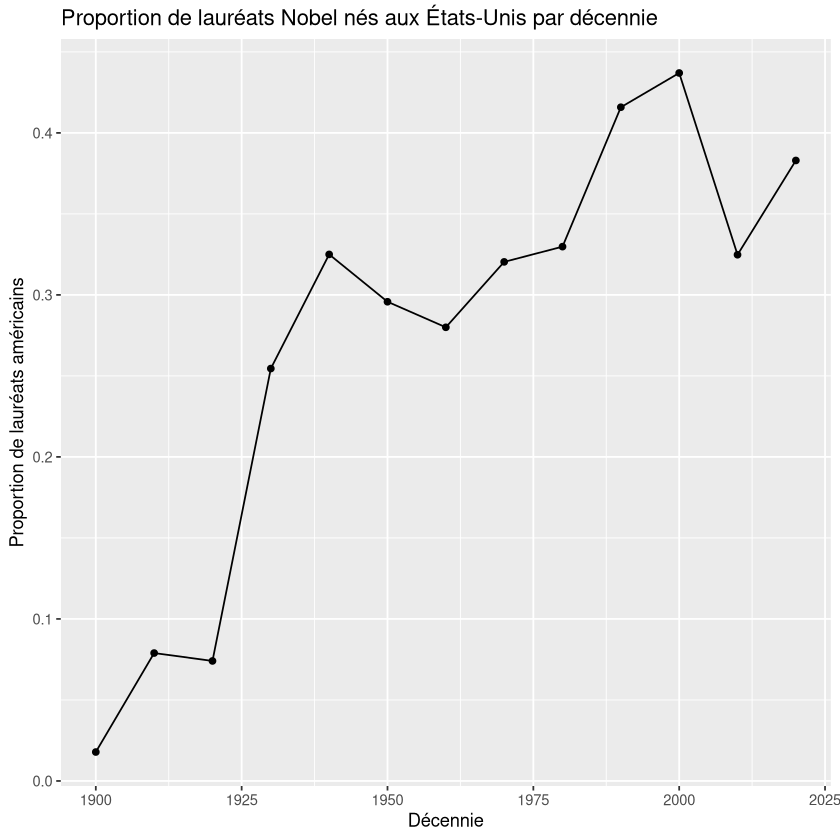

In [51]:
# 3. Tracer l'évolution avec ggplot
ggplot(prop_usa_decade, aes(x = decade, y = prop_usa)) +
  geom_line() +
  geom_point() +
  labs(
    title = "Proportion de lauréats Nobel nés aux États-Unis par décennie",
    x = "Décennie",
    y = "Proportion de lauréats américains"
  )

Proportion de lauréates

In [53]:
female_by_decade <- nobel %>%
  mutate(
    decade = floor(year / 10) * 10,
    female_winner = sex == "Female"
  ) %>%
  group_by(decade, category) %>%
  summarise(
    prop_winner = mean(female_winner, na.rm = TRUE),
    .groups = "drop"
  )

max_female <- female_by_decade %>%
  group_by(category) %>%
  slice_max(prop_winner, n = 1, with_ties = TRUE) %>%
  ungroup()

max_female

decade,category,prop_winner
<dbl>,<chr>,<dbl>
2020,Chemistry,0.3000000
2020,Economics,0.1111111
2020,Literature,0.5000000
2000,Medicine,0.1538462
2010,Peace,0.5000000
2020,Peace,0.5000000
2020,Physics,0.1666667


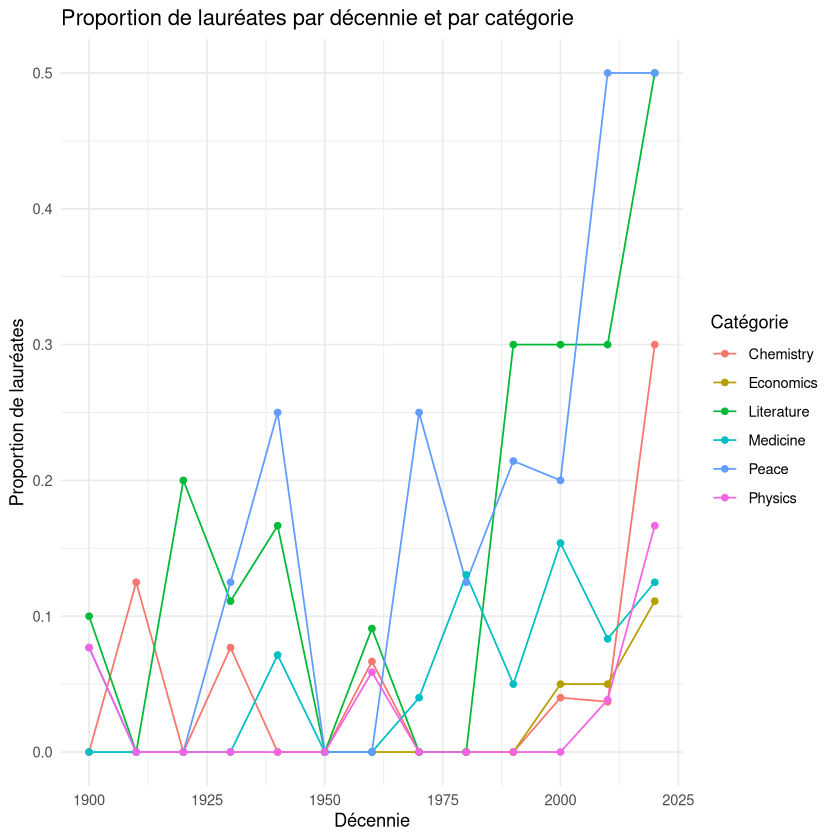

In [54]:
ggplot(female_by_decade, aes(x = decade, y = prop_winner, color = category)) +
  geom_line() +
  geom_point() +
  labs(
    title = "Proportion de lauréates par décennie et par catégorie",
    x = "Décennie",
    y = "Proportion de lauréates",
    color = "Catégorie"
  ) +
  theme_minimal()

Première femme lauréate

In [57]:
first_woman <- nobel %>%
  filter(sex == "Female") %>%
  arrange(year) %>%
  slice(1)

first_woman_name <- first_woman %>% pull(full_name)

first_woman_category <- first_woman %>% pull(category)

first_woman_name
first_woman_category
first_woman


[1] "Marie Curie, née Sklodowska"

[1] "Physics"

year,category,prize,motivation,prize_share,laureate_id,laureate_type,full_name,birth_date,birth_city,birth_country,sex,organization_name,organization_city,organization_country,death_date,death_city,death_country
<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<date>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<date>,<chr>,<chr>
1903,Physics,The Nobel Prize in Physics 1903,"""in recognition of the extraordinary services they have rendered by their joint researches on the radiation phenomena discovered by Professor Henri Becquerel""",1/4,6,Individual,"Marie Curie, née Sklodowska",1867-11-07,Warsaw,Russian Empire (Poland),Female,NA,NA,NA,1934-07-04,Sallanches,France


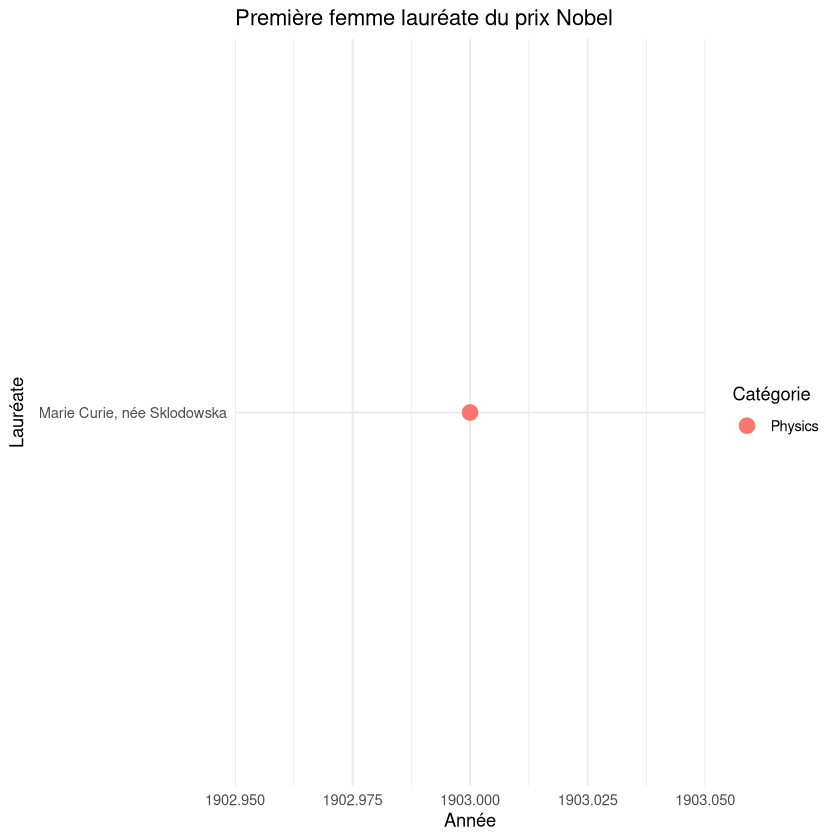

In [58]:
ggplot(first_woman, aes(x = year, y = full_name, color = category)) +
  geom_point(size = 4) +
  labs(
    title = "Première femme lauréate du prix Nobel",
    x = "Année",
    y = "Lauréate",
    color = "Catégorie"
  ) +
  theme_minimal()

Lauréats plusieurs fois récompensés

In [62]:
repeats <- nobel %>%
  count(full_name, sort = TRUE) %>%
  filter(n > 1)

repeats

full_name,n
<chr>,<int>
Comité international de la Croix Rouge (International Committee of the Red Cross),3
Frederick Sanger,2
John Bardeen,2
Linus Carl Pauling,2
"Marie Curie, née Sklodowska",2
Office of the United Nations High Commissioner for Refugees (UNHCR),2


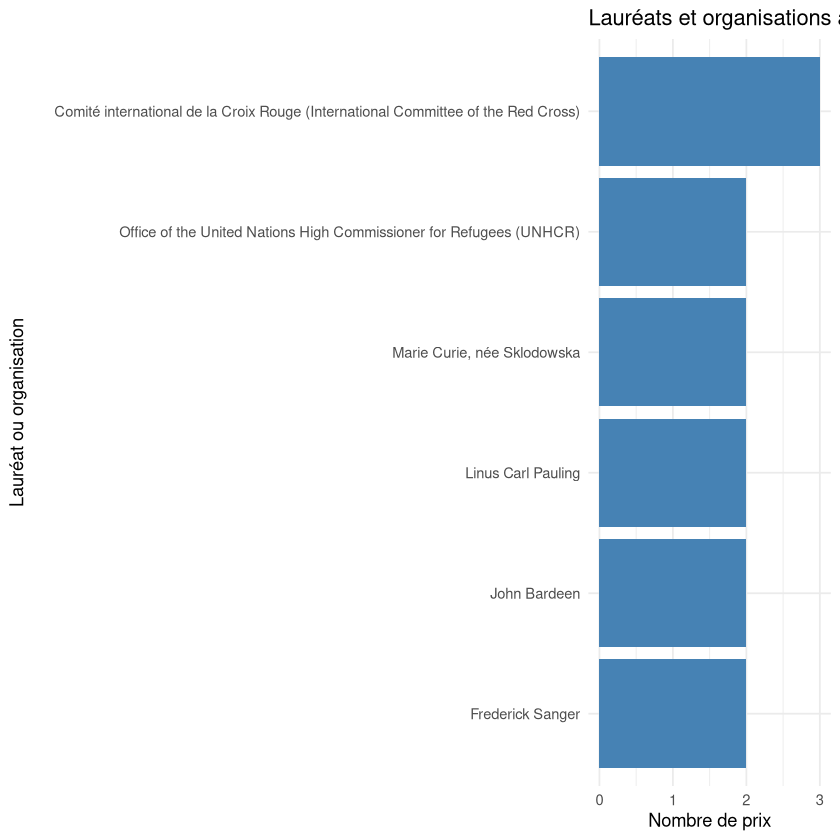

In [63]:
ggplot(repeats, aes(x = reorder(full_name, n), y = n)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Lauréats et organisations ayant reçu plusieurs prix",
    x = "Lauréat ou organisation",
    y = "Nombre de prix"
  ) +
  theme_minimal()

les hommes sont majoritaires ;
les États-Unis sont le pays de naissance le plus représenté ;
les catégories Literature et Peace comptent chacune 12 lauréates entre 1901 et 2000 ;
Marie Curie est la première femme lauréate ;
certains lauréats et organisations ont reçu plusieurs prix.